In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

Carga de datos


In [12]:
df = pd.read_csv("../data/telecom_churn.csv")
df.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


# Customer Churn Analysis

## Objetivo
El objetivo de este análisis es identificar patrones y variables asociadas al abandono de clientes (churn) en una empresa de telecomunicaciones.

## Preguntas de negocio
- ¿Qué características tienen los clientes que abandonan?
- ¿Qué variables están más relacionadas con el churn?
- ¿Cómo se podría anticipar este comportamiento?

Exploracion inicial

In [13]:
print("Dimensiones del dataset:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nEstadísticas descriptivas:")
df.describe()

Dimensiones del dataset: (3333, 11)

Tipos de datos:
Churn                int64
AccountWeeks         int64
ContractRenewal      int64
DataPlan             int64
DataUsage          float64
CustServCalls        int64
DayMins            float64
DayCalls             int64
MonthlyCharge      float64
OverageFee         float64
RoamMins           float64
dtype: object

Valores nulos por columna:
Churn              0
AccountWeeks       0
ContractRenewal    0
DataPlan           0
DataUsage          0
CustServCalls      0
DayMins            0
DayCalls           0
MonthlyCharge      0
OverageFee         0
RoamMins           0
dtype: int64

Estadísticas descriptivas:


,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,0.144914,101.064806,0.903090,0.276628,0.816475,1.562856,179.775098,100.435644,56.305161,10.051488,10.237294
std,0.352067,39.822106,0.295879,0.447398,1.272668,1.315491,54.467389,20.069084,16.426032,2.535712,2.791840
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
25%,0.000000,74.000000,1.000000,0.000000,0.000000,1.000000,143.700000,87.000000,45.000000,8.330000,8.500000
50%,0.000000,101.000000,1.000000,0.000000,0.000000,1.000000,179.400000,101.000000,53.500000,10.070000,10.300000
75%,0.000000,127.000000,1.000000,1.000000,1.780000,2.000000,216.400000,114.000000,66.200000,11.770000,12.100000
max,1.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.800000,165.000000,111.300000,18.190000,20.000000


## Exploración inicial

El dataset contiene información de 3333 clientes y 11 variables, todas de tipo numérico.  
No se observan valores nulos, lo que simplifica el proceso de limpieza de datos.

La variable objetivo es **Churn**, la cual indica si el cliente abandona el servicio (1) o permanece (0).

Distribuicion de la variable objetivo

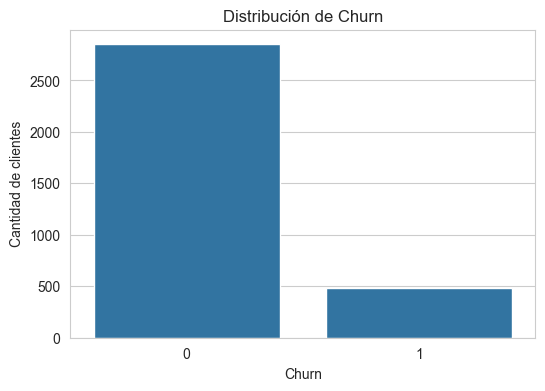

Churn
0    85.508551
1    14.491449
Name: proportion, dtype: float64


In [14]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Churn")
plt.title("Distribución de Churn")
plt.xlabel("Churn")
plt.ylabel("Cantidad de clientes")
plt.show()

print(df["Churn"].value_counts(normalize=True) * 100)

## Distribución de la variable objetivo

Se observa que la mayoría de los clientes no abandona la compañía, mientras que una proporción menor sí presenta churn.

Esto indica un leve desbalance en la variable objetivo, lo que debe considerarse en etapas posteriores de modelamiento.

Histogramas de variables numéricas

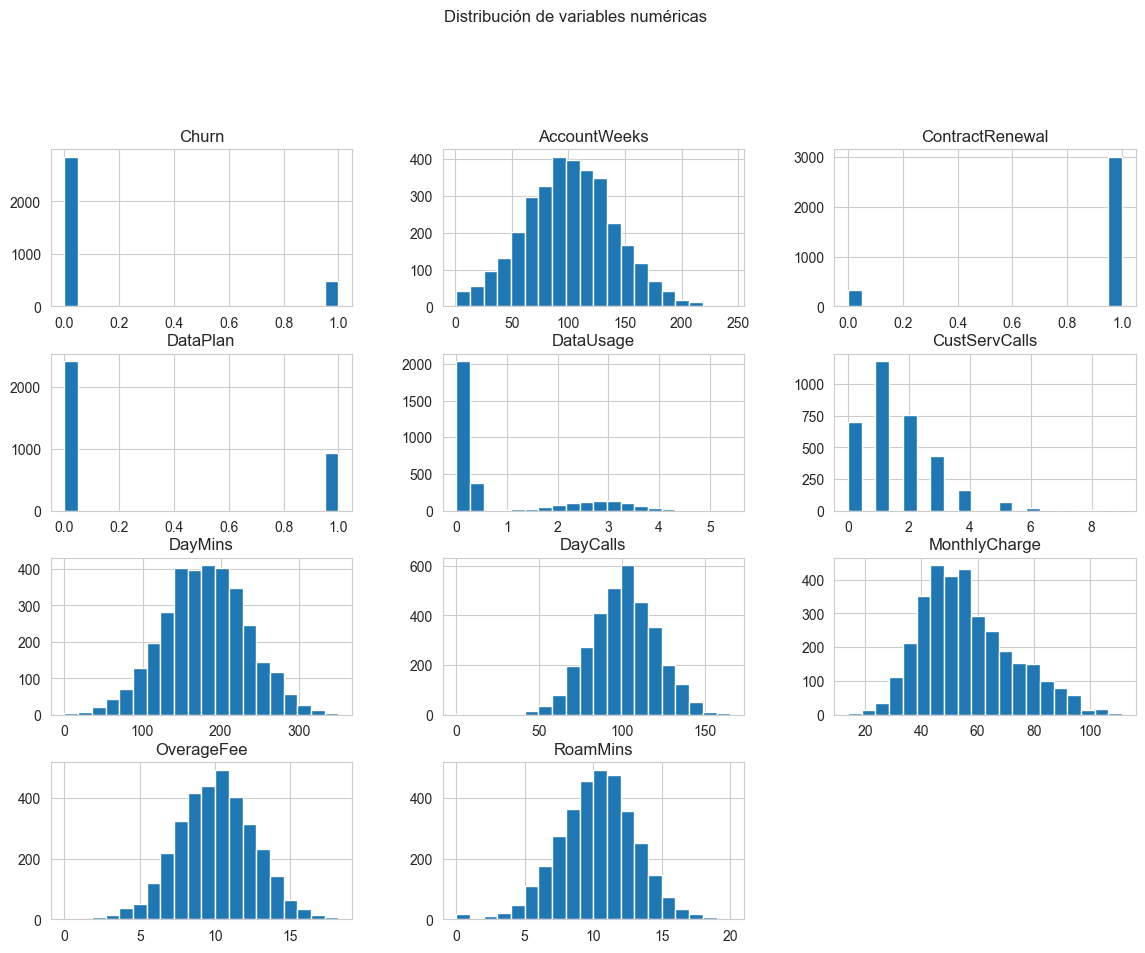

In [15]:
df.hist(figsize=(14,10), bins=20)
plt.suptitle("Distribución de variables numéricas", y=1.02)
plt.show()

## Distribución de variables

Las variables presentan distintas distribuciones. Algunas parecen simétricas, mientras que otras muestran sesgos o dispersión.

Esto sugiere que los clientes tienen comportamientos heterogéneos en términos de uso del servicio, cargos y actividad.

Correlacion

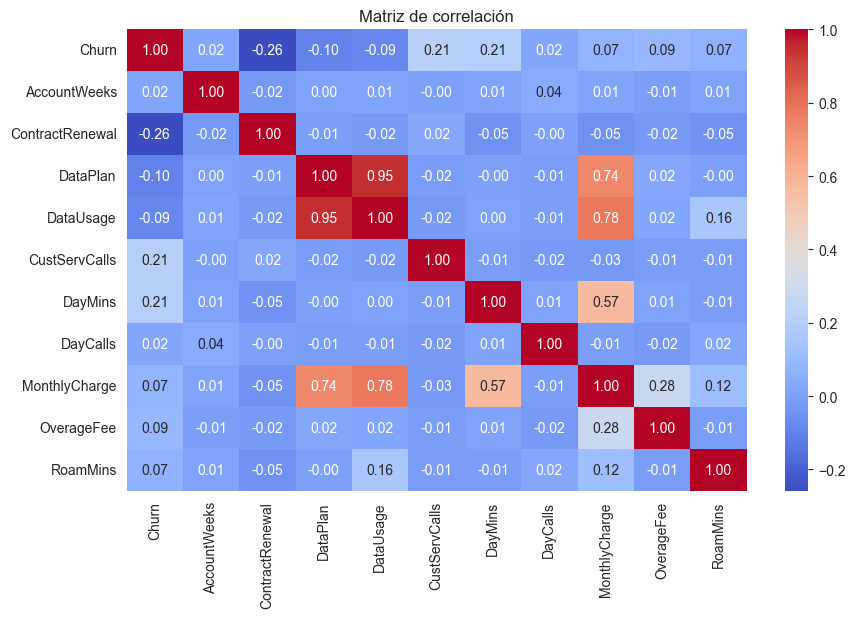

In [16]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

## Análisis de correlación

Se observan relaciones relevantes entre algunas variables:

- `DayMins` y `MonthlyCharge` muestran una correlación positiva
- `DataPlan` y `DataUsage` también están relacionadas

Respecto al churn, algunas variables presentan mayor correlación, lo que sugiere que podrían ser relevantes para modelos predictivos.

In [31]:
corr = df.corr()["Churn"].sort_values(ascending=False)
corr

Churn              1.000000
CustServCalls      0.208750
DayMins            0.205151
OverageFee         0.092812
MonthlyCharge      0.072313
RoamMins           0.068239
DayCalls           0.018459
AccountWeeks       0.016541
DataUsage         -0.087195
DataPlan          -0.102148
ContractRenewal   -0.259852
Name: Churn, dtype: float64

Las variables más asociadas al churn serán consideradas como potenciales predictores en etapas posteriores.

Churn por variable

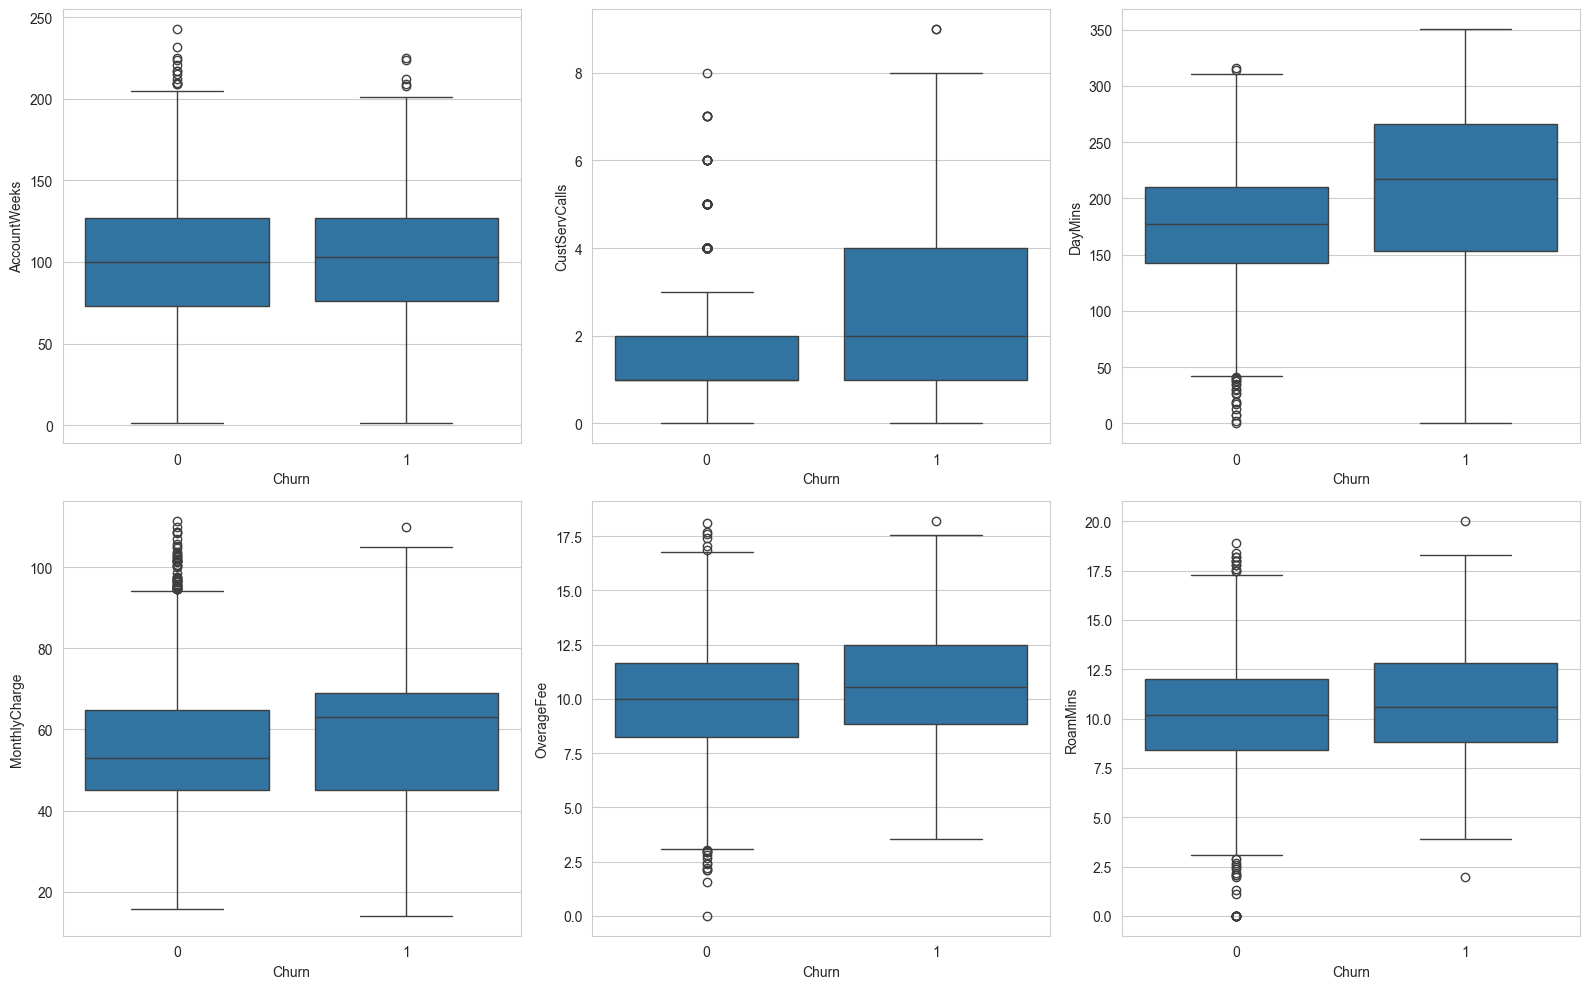

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

sns.boxplot(data=df, x="Churn", y="AccountWeeks", ax=axes[0,0])
sns.boxplot(data=df, x="Churn", y="CustServCalls", ax=axes[0,1])
sns.boxplot(data=df, x="Churn", y="DayMins", ax=axes[0,2])
sns.boxplot(data=df, x="Churn", y="MonthlyCharge", ax=axes[1,0])
sns.boxplot(data=df, x="Churn", y="OverageFee", ax=axes[1,1])
sns.boxplot(data=df, x="Churn", y="RoamMins", ax=axes[1,2])

plt.tight_layout()
plt.show()

## Comparación de variables según churn

Se observan diferencias claras entre clientes que abandonan y los que no:

- Los clientes con churn tienden a tener más llamadas al servicio al cliente (`CustServCalls`)
- Presentan mayores cargos mensuales (`MonthlyCharge`)
- También pueden mostrar mayor uso del servicio (`DayMins`)

Esto sugiere que el churn podría estar relacionado con insatisfacción o altos costos.

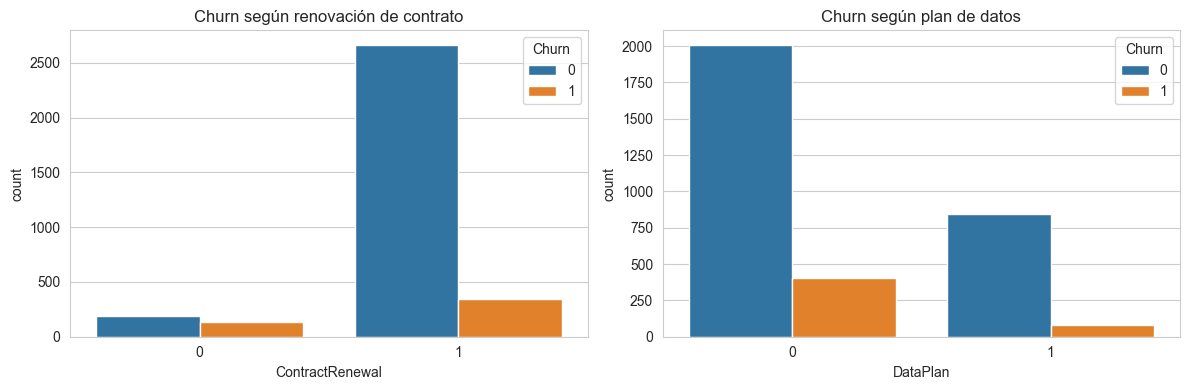

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="ContractRenewal", hue="Churn", ax=axes[0])
axes[0].set_title("Churn según renovación de contrato")

sns.countplot(data=df, x="DataPlan", hue="Churn", ax=axes[1])
axes[1].set_title("Churn según plan de datos")

plt.tight_layout()
plt.show()

## Variables categóricas relevantes

- Los clientes que no renuevan contrato presentan mayor churn
- La presencia de un plan de datos también influye en el comportamiento del cliente

Estas variables pueden ser clave para segmentar clientes en riesgo.

## Conclusiones del análisis exploratorio

A partir del análisis realizado, se identifican los siguientes puntos clave:

- Variables más relevantes:
  - CustServCalls
  - MonthlyCharge
  - DayMins
  - ContractRenewal

- Posibles causas de churn:
  - Alta interacción con servicio al cliente (posible insatisfacción)
  - Altos costos del servicio
  - Falta de compromiso contractual

## Próximos pasos

En la siguiente etapa, se desarrollarán modelos de machine learning para predecir el churn y evaluar qué variables tienen mayor impacto en la predicción.

Separacion por variables predictoras y target

In [32]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (2666, 10)
Test shape: (667, 10)


Escalado

In [33]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Modelo 1

In [34]:
log_model = LogisticRegression(random_state=42)
log_model.fit(X_train_scaled, y_train)

y_pred_log = log_model.predict(X_test_scaled)
y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

In [35]:
print("LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1-score:", f1_score(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_log))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

LOGISTIC REGRESSION
Accuracy: 0.8575712143928036
Precision: 0.5263157894736842
Recall: 0.20618556701030927
F1-score: 0.2962962962962963
ROC-AUC: 0.8091155724362452

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92       570
           1       0.53      0.21      0.30        97

    accuracy                           0.86       667
   macro avg       0.70      0.59      0.61       667
weighted avg       0.83      0.86      0.83       667



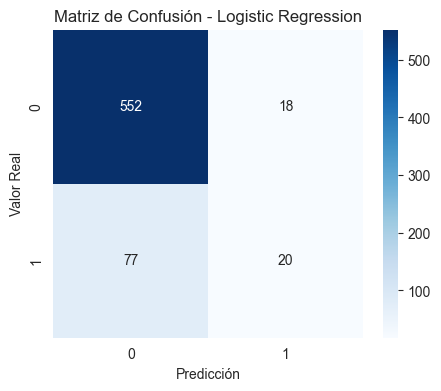

In [36]:
cm_log = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(5,4))
sns.heatmap(cm_log, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de Confusión - Logistic Regression")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

Modelo 2


In [37]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [38]:
print("RANDOM FOREST")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST
Accuracy: 0.9250374812593704
Precision: 0.821917808219178
Recall: 0.6185567010309279
F1-score: 0.7058823529411765
ROC-AUC: 0.8648399348887682

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       570
           1       0.82      0.62      0.71        97

    accuracy                           0.93       667
   macro avg       0.88      0.80      0.83       667
weighted avg       0.92      0.93      0.92       667



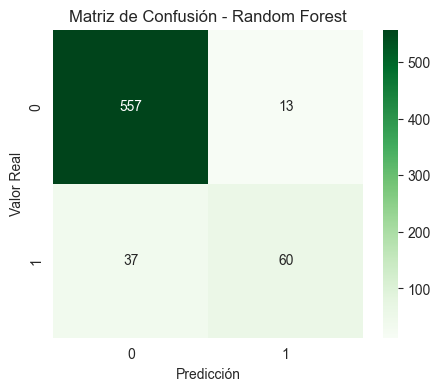

In [39]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens")
plt.title("Matriz de Confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

Curva ROC comparativa

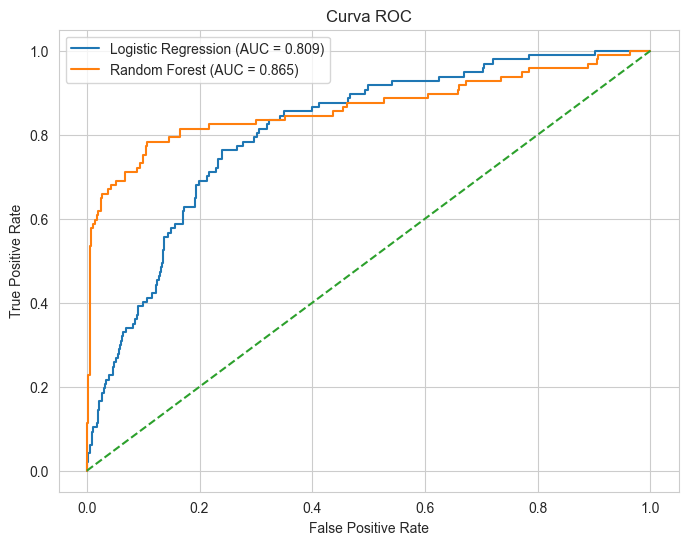

In [40]:
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8,6))
plt.plot(fpr_log, tpr_log, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_log):.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC")
plt.legend()
plt.show()

## Curva ROC

La curva ROC permite evaluar la capacidad del modelo para distinguir entre clientes que abandonan y los que no.

El modelo Random Forest presenta un mejor desempeño, reflejado en un mayor valor de AUC, lo que indica una mejor capacidad de clasificación.

Importancia de variables en random forest

In [41]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance

,Feature,Importance
5,DayMins,0.221507
7,MonthlyCharge,0.181466
4,CustServCalls,0.168102
3,DataUsage,0.086075
1,ContractRenewal,0.085640
8,OverageFee,0.072812
9,RoamMins,0.065548
2,DataPlan,0.042784
6,DayCalls,0.040514
0,AccountWeeks,0.035551


## Importancia de variables

Las variables más relevantes para la predicción del churn son:

- CustServCalls
- MonthlyCharge
- DayMins
- OverageFee

Esto indica que el churn está fuertemente relacionado con la experiencia del cliente y el costo del servicio.

Clientes con más interacciones con servicio al cliente y mayores cargos presentan mayor probabilidad de abandono.

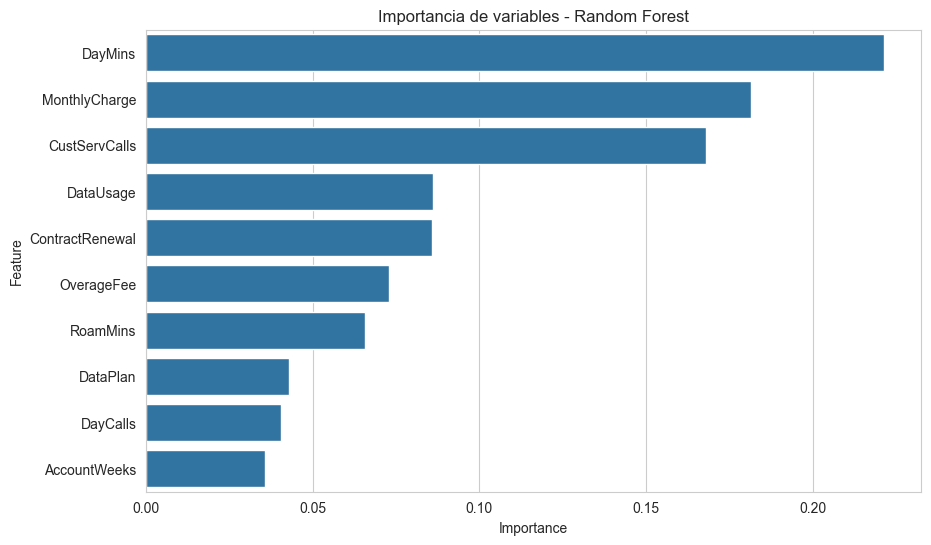

In [42]:
plt.figure(figsize=(10,6))
sns.barplot(data=feature_importance, x="Importance", y="Feature")
plt.title("Importancia de variables - Random Forest")
plt.show()

Comparacion de modelos

In [43]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.857571,0.526316,0.206186,0.296296,0.809116
1,Random Forest,0.925037,0.821918,0.618557,0.705882,0.864840


## Evaluación de modelos

Ambos modelos fueron evaluados utilizando métricas como accuracy, precision, recall, F1-score y ROC-AUC.

El modelo Random Forest presenta un mejor desempeño general en comparación con Logistic Regression, especialmente en métricas como recall y ROC-AUC.

En este contexto, el recall es especialmente importante, ya que permite identificar la mayor cantidad posible de clientes que podrían abandonar el servicio.

## Comparación de modelos

- Logistic Regression:
  - Modelo simple e interpretable
  - Sirve como baseline

- Random Forest:
  - Mejor desempeño predictivo
  - Captura relaciones no lineales
  - Mayor capacidad para detectar churn

En base a los resultados obtenidos, Random Forest se posiciona como el modelo más adecuado para este problema.

## Conclusión final

Este proyecto desarrolló modelos de machine learning para predecir el churn en clientes de telecomunicaciones.

A partir del análisis exploratorio y los modelos entrenados, se identificó que variables como la cantidad de llamadas al servicio al cliente, los cargos mensuales y el uso del servicio son factores clave en la probabilidad de abandono.

El modelo Random Forest demostró ser el más efectivo, logrando un mejor desempeño en métricas clave como recall y ROC-AUC.

Desde una perspectiva de negocio, este modelo permite:

- Identificar clientes en riesgo antes de que abandonen
- Implementar estrategias de retención más efectivas
- Reducir la pérdida de clientes

Como mejora futura, se podrían incorporar más variables, ajustar hiperparámetros y probar modelos más avanzados.